In [10]:
import os

# Names of the three datasets
dataset_files = [
    "Mri_clean_normal_224x224.zip",
    "Mri_clean_tumor_224x224.zip",
    "Mri_clean_Stroke_224x224.zip"
]

print("CHECKING MRI DATASETS")
print("=" * 50)

for filename in dataset_files:
    filepath = os.path.join("/content", filename)

    if os.path.exists(filepath):
        size_mb = os.path.getsize(filepath) / (1024 * 1024)
        print(f"FOUND: {filename} ({size_mb:.2f} MB)")
    else:
        print(f"NOT FOUND: {filename}")

print("=" * 50)

CHECKING MRI DATASETS
FOUND: Mri_clean_normal_224x224.zip (11.75 MB)
FOUND: Mri_clean_tumor_224x224.zip (12.37 MB)
FOUND: Mri_clean_Stroke_224x224.zip (19.27 MB)


In [11]:
import os
import zipfile
import shutil
from pathlib import Path
from collections import Counter

# 1. DEFINE PATHS

base_dir = "/content"
combined_dir = "/content/Combined_MRI_Dataset"
extracted_dir = "/content/MRI_Extracted"

datasets = {
    "Normal": "/content/Mri_clean_normal_224x224.zip",
    "Tumor": "/content/Mri_clean_tumor_224x224.zip",
    "Stroke": "/content/Mri_clean_Stroke_224x224.zip"
}

# Supported image formats
image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}


# CHECK THAT ALL ZIP FILES EXIST


for class_name, zip_path in datasets.items():
    if not os.path.isfile(zip_path):
        raise FileNotFoundError(
            f"Dataset not found: {zip_path}\n"
            "Run Step 1 and check your filenames."
        )

print("All three ZIP files were found.")

# CREATE OUTPUT FOLDERS


# Remove previous output folders created by this script.

for folder in [combined_dir, extracted_dir]:
    if os.path.exists(folder):
        shutil.rmtree(folder)

os.makedirs(combined_dir)
os.makedirs(extracted_dir)


# EXTRACT EACH ZIP AND COMBINE THE IMAGES

image_counts = Counter()

for class_name, zip_path in datasets.items():

    print(f"\nProcessing {class_name} dataset...")

    # Create a separate extraction directory
    class_extract_dir = os.path.join(
        extracted_dir, class_name
    )
    os.makedirs(class_extract_dir)

    # Create the destination class folder
    class_output_dir = os.path.join(
        combined_dir, class_name
    )
    os.makedirs(class_output_dir)

    # Safely extract the ZIP
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(class_extract_dir)

    # Find all supported images recursively
    image_paths = [
        path
        for path in Path(class_extract_dir).rglob("*")
        if path.is_file()
        and path.suffix.lower() in image_extensions
    ]

    copied = 0

    for index, image_path in enumerate(image_paths):

        new_filename = (
            f"{class_name}_{index:06d}"
            f"{image_path.suffix.lower()}"
        )

        destination = os.path.join(
            class_output_dir, new_filename
        )

        shutil.copy2(image_path, destination)
        copied += 1

    image_counts[class_name] = copied

    print(f"{class_name} images copied: {copied}")

# DISPLAY FINAL DATASET SUMMARY
total_images = sum(image_counts.values())

print("\n" + "=" * 50)
print("COMBINED MRI DATASET SUMMARY")
print("=" * 50)

for class_name in ["Normal", "Stroke", "Tumor"]:
    print(f"{class_name}: {image_counts[class_name]} images")

print("-" * 50)
print(f"TOTAL IMAGES: {total_images}")
print(f"OUTPUT FOLDER: {combined_dir}")
print("=" * 50)

if total_images == 0:
    raise ValueError(
        "No supported images were found. "
        "Check the contents of your ZIP files."
    )

print("\nDataset combination completed successfully!")

All three ZIP files were found.

Processing Normal dataset...
Normal images copied: 1056

Processing Tumor dataset...
Tumor images copied: 952

Processing Stroke dataset...
Stroke images copied: 1299

COMBINED MRI DATASET SUMMARY
Normal: 1056 images
Stroke: 1299 images
Tumor: 952 images
--------------------------------------------------
TOTAL IMAGES: 3307
OUTPUT FOLDER: /content/Combined_MRI_Dataset

Dataset combination completed successfully!


In [12]:
import os
import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter

# DEFINE PATHS

source_dir = Path("/content/Combined_MRI_Dataset")
split_dir = Path("/content/MRI_Split_Dataset")

classes = ["Normal", "Stroke", "Tumor"]

# CHECK SOURCE DATASET

if not source_dir.exists():
    raise FileNotFoundError(
        "Combined dataset not found. Complete Step 2 first."
    )

for class_name in classes:
    if not (source_dir / class_name).is_dir():
        raise FileNotFoundError(
            f"Missing class folder: {source_dir / class_name}"
        )

# Recreate the split folders
if split_dir.exists():
    shutil.rmtree(split_dir)

for split_name in ["train", "val", "test"]:
    for class_name in classes:
        (split_dir / split_name / class_name).mkdir(
            parents=True,
            exist_ok=True
        )


# SPLIT EACH CLASS

summary = {}

for class_name in classes:

    class_dir = source_dir / class_name

    image_paths = [
        path for path in class_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }
    ]

    if len(image_paths) < 3:
        raise ValueError(
            f"Not enough images in {class_name}."
        )

    # First split: 70% training, 30% remaining
    train_paths, remaining_paths = train_test_split(
        image_paths,
        test_size=0.30,
        random_state=42,
        shuffle=True
    )

    # Second split: divide the remaining 30% equally
    val_paths, test_paths = train_test_split(
        remaining_paths,
        test_size=0.50,
        random_state=42,
        shuffle=True
    )

    split_files = {
        "train": train_paths,
        "val": val_paths,
        "test": test_paths
    }

    for split_name, paths in split_files.items():

        destination_dir = split_dir / split_name / class_name

        for image_path in paths:
            shutil.copy2(
                image_path,
                destination_dir / image_path.name
            )

    summary[class_name] = {
        split_name: len(paths)
        for split_name, paths in split_files.items()
    }


# DISPLAY SPLIT SUMMARY

print("\nDATASET SPLIT SUMMARY")
print("=" * 65)

for class_name in classes:
    print(f"\n{class_name}")

    for split_name in ["train", "val", "test"]:
        print(
            f"  {split_name}: "
            f"{summary[class_name][split_name]}"
        )

print("\nTOTALS")

for split_name in ["train", "val", "test"]:

    total = sum(
        summary[class_name][split_name]
        for class_name in classes
    )

    print(f"{split_name}: {total} images")

print(f"\nSplit dataset saved to: {split_dir}")


DATASET SPLIT SUMMARY

Normal
  train: 739
  val: 158
  test: 159

Stroke
  train: 909
  val: 195
  test: 195

Tumor
  train: 666
  val: 143
  test: 143

TOTALS
train: 2314 images
val: 496 images
test: 497 images

Split dataset saved to: /content/MRI_Split_Dataset


In [13]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.densenet import preprocess_input

# CONFIGURATION

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

base_dir = "/content/MRI_Split_Dataset"

train_dir = f"{base_dir}/train"
val_dir = f"{base_dir}/val"
test_dir = f"{base_dir}/test"

# CREATE DATA GENERATORS

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

val_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)


# LOAD TRAINING IMAGES

train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    color_mode="rgb",
    shuffle=True,
    seed=SEED
)


# LOAD VALIDATION IMAGES

val_data = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    color_mode="rgb",
    shuffle=False
)

# LOAD TEST IMAGES

test_data = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    color_mode="rgb",
    shuffle=False
)

# DISPLAY DATASET INFORMATION

print("\nCLASS LABELS:")
print(train_data.class_indices)

print("\nDATASET INFORMATION")
print("Training images:", train_data.samples)
print("Validation images:", val_data.samples)
print("Testing images:", test_data.samples)

images, labels = next(train_data)

print("\nBATCH VERIFICATION")
print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Pixel range:", images.min(), "to", images.max())

Found 2314 images belonging to 3 classes.
Found 496 images belonging to 3 classes.
Found 497 images belonging to 3 classes.

CLASS LABELS:
{'Normal': 0, 'Stroke': 1, 'Tumor': 2}

DATASET INFORMATION
Training images: 2314
Validation images: 496
Testing images: 497

BATCH VERIFICATION
Image shape: (32, 224, 224, 3)
Label shape: (32, 3)
Pixel range: -2.117904 to 2.64


In [14]:
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dropout,
    Dense
)
from tensorflow.keras.models import Model


IMG_SIZE = (224, 224)
NUM_CLASSES = 3

# LOAD PRETRAINED DENSENET121

base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers for initial training
base_model.trainable = False

# ADD THE CLASSIFICATION LAYERS

inputs = Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = GlobalAveragePooling2D()(x)

x = Dropout(0.4)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classification_output"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="DenseNet121_MRI_Classifier"
)

# COMPILE THE MODEL

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# DISPLAY MODEL

model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DenseNet121_MRI_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 3)              │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,040,579 (26.86 MB)

 Trainable params: 3,075 (12.01 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [15]:
import os
import tensorflow as tf

# CREATE MODEL SAVE FOLDER

save_dir = "/content/densenet_results"
os.makedirs(save_dir, exist_ok=True)

best_model_path = os.path.join(
    save_dir,
    "best_densenet121.keras"
)

# DEFINE CALLBACKS

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=best_model_path,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    mode="min",
    verbose=1
)


# TRAIN THE MODEL

EPOCHS = 20

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

print("\nTRAINING COMPLETED!")
print("Best model saved to:", best_model_path)

Epoch 1/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step - accuracy: 0.3801 - loss: 1.4950
Epoch 1: val_loss improved from None to 1.01837, saving model to /content/densenet_results/best_densenet121.keras

Epoch 1: finished saving model to /content/densenet_results/best_densenet121.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 75s 643ms/step - accuracy: 0.3954 - loss: 1.4160 - val_accuracy: 0.5000 - val_loss: 1.0184 - learning_rate: 1.0000e-04
Epoch 2/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.4502 - loss: 1.2767
Epoch 2: val_loss improved from 1.01837 to 0.87680, saving model to /content/densenet_results/best_densenet121.keras

Epoch 2: finished saving model to /content/densenet_results/best_densenet121.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 10s 130ms/step - accuracy: 0.4581 - loss: 1.2382 - val_accuracy: 0.6028 - val_loss: 0.8768 - learning_rate: 1.0000e-04
Epoch 3/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.4882 - loss: 1.1331
Epoch 3: val_loss improved from 0.87680 to 0.77632, s

Best DenseNet121 model loaded successfully.
16/16 ━━━━━━━━━━━━━━━━━━━━ 26s 835ms/step - accuracy: 0.8350 - loss: 0.4484

Test Loss: 0.4484
Test Accuracy: 83.50%
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 843ms/step

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.8308    0.6792    0.7474       159
      Stroke     0.8142    0.9436    0.8741       195
       Tumor     0.8723    0.8601    0.8662       143

    accuracy                         0.8350       497
   macro avg     0.8391    0.8277    0.8292       497
weighted avg     0.8362    0.8350    0.8313       497



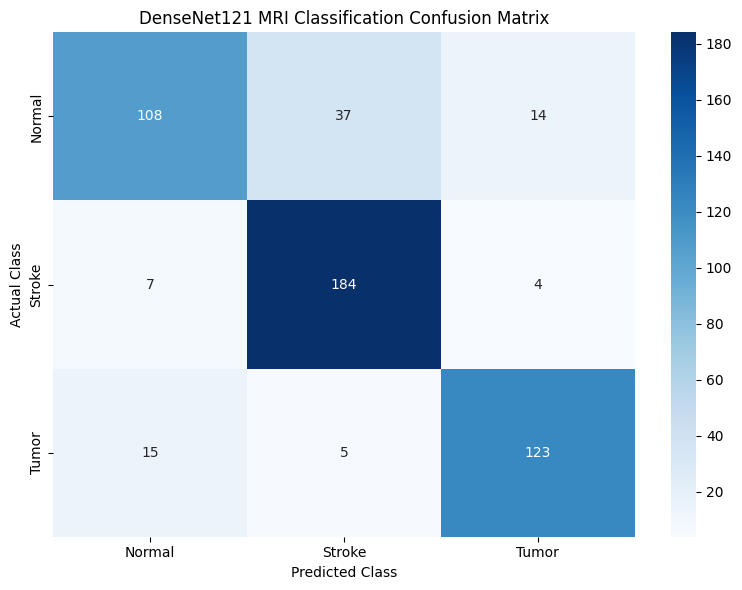

In [16]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# LOAD THE BEST SAVED MODEL

best_model_path = (
    "/content/densenet_results/best_densenet121.keras"
)

best_model = tf.keras.models.load_model(best_model_path)

print("Best DenseNet121 model loaded successfully.")


# EVALUATE TEST DATASET

test_loss, test_accuracy = best_model.evaluate(
    test_data,
    verbose=1
)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# GENERATE PREDICTIONS

test_data.reset()

probabilities = best_model.predict(
    test_data,
    verbose=1
)

y_pred = np.argmax(probabilities, axis=1)
y_true = test_data.classes

class_names = [
    name
    for name, index in sorted(
        test_data.class_indices.items(),
        key=lambda item: item[1]
    )
]

# CLASSIFICATION REPORT

print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# CONFUSION MATRIX

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("DenseNet121 MRI Classification Confusion Matrix")
plt.tight_layout()
plt.show()

In [17]:
import os
import tensorflow as tf

# --------------------------------------------------
# 1. LOAD THE BEST MODEL FROM INITIAL TRAINING
# --------------------------------------------------

initial_model_path = (
    "/content/densenet_results/best_densenet121.keras"
)

model = tf.keras.models.load_model(initial_model_path)

print("Initial DenseNet121 model loaded.")

# --------------------------------------------------
# 2. ACCESS THE DENSENET121 BACKBONE
# --------------------------------------------------

base_model = model.get_layer("densenet121")

# Unfreeze the backbone so selected layers can be trained
base_model.trainable = True

# Freeze all layers initially
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze the final 40 layers, keeping Batch Normalization
# layers frozen to reduce instability during fine-tuning.
for layer in base_model.layers[-40:]:
    if not isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True

print("\nTrainable backbone layers:",
      sum(layer.trainable for layer in base_model.layers))

# --------------------------------------------------
# 3. RECOMPILE WITH A SMALL LEARNING RATE
# --------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# --------------------------------------------------
# 4. CREATE A SEPARATE SAVE DIRECTORY
# --------------------------------------------------

fine_tune_dir = "/content/densenet_finetuned"
os.makedirs(fine_tune_dir, exist_ok=True)

fine_tuned_model_path = os.path.join(
    fine_tune_dir,
    "best_densenet121_finetuned.keras"
)

# --------------------------------------------------
# 5. DEFINE CALLBACKS
# --------------------------------------------------

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=fine_tuned_model_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        mode="min",
        verbose=1
    )
]

# --------------------------------------------------
# 6. FINE-TUNE THE MODEL
# --------------------------------------------------

fine_tune_history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)

print("\nFine-tuning completed.")
print("Saved model:", fine_tuned_model_path)

Initial DenseNet121 model loaded.

Trainable backbone layers: 29
Epoch 1/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.7615 - loss: 0.5816
Epoch 1: val_loss improved from None to 0.41265, saving model to /content/densenet_finetuned/best_densenet121_finetuned.keras

Epoch 1: finished saving model to /content/densenet_finetuned/best_densenet121_finetuned.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 71s 631ms/step - accuracy: 0.7580 - loss: 0.5822 - val_accuracy: 0.8427 - val_loss: 0.4126 - learning_rate: 1.0000e-05
Epoch 2/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.7570 - loss: 0.5554
Epoch 2: val_loss improved from 0.41265 to 0.39882, saving model to /content/densenet_finetuned/best_densenet121_finetuned.keras

Epoch 2: finished saving model to /content/densenet_finetuned/best_densenet121_finetuned.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 11s 145ms/step - accuracy: 0.7636 - loss: 0.5435 - val_accuracy: 0.8427 - val_loss: 0.3988 - learning_rate: 1.0000e-05
Epoch 3/15
73/73 ━━━━━━━

In [18]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# GET LABELS FROM THE TRAINING DATASET

class_labels = np.unique(train_data.classes)

# CALCULATE BALANCED CLASS WEIGHTS

weights = compute_class_weight(
    class_weight="balanced",
    classes=class_labels,
    y=train_data.classes
)

class_weights = {
    int(class_label): float(weight)
    for class_label, weight in zip(class_labels, weights)
}

# DISPLAY THE RESULTS

print("CLASS MAPPING:")
print(train_data.class_indices)

print("\nCALCULATED CLASS WEIGHTS:")

for class_name, class_index in train_data.class_indices.items():
    print(
        f"{class_name}: "
        f"{class_weights[class_index]:.4f}"
    )

CLASS MAPPING:
{'Normal': 0, 'Stroke': 1, 'Tumor': 2}

CALCULATED CLASS WEIGHTS:
Normal: 1.0438
Stroke: 0.8486
Tumor: 1.1582


In [19]:
import os
import tensorflow as tf

# LOAD THE ORIGINAL BEST MODEL

original_model_path = (
    "/content/densenet_results/best_densenet121.keras"
)

weighted_model = tf.keras.models.load_model(
    original_model_path
)

print("Original model loaded for class-weighted training.")

# COMPILE THE MODEL

weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# CREATE SAVE DIRECTORY

weighted_dir = "/content/densenet_class_weighted"
os.makedirs(weighted_dir, exist_ok=True)

weighted_model_path = os.path.join(
    weighted_dir,
    "best_class_weighted.keras"
)

# DEFINE CALLBACKS

weighted_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=weighted_model_path,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        mode="min",
        verbose=1
    )
]

# TRAIN USING CLASS WEIGHTS

train_data.reset()
val_data.reset()

weighted_history = weighted_model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    class_weight=class_weights,
    callbacks=weighted_callbacks,
    verbose=1
)

print("\nClass-weighted training completed.")
print("Saved model:", weighted_model_path)

Original model loaded for class-weighted training.
Epoch 1/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step - accuracy: 0.7455 - loss: 0.5722
Epoch 1: val_loss improved from None to 0.42677, saving model to /content/densenet_class_weighted/best_class_weighted.keras

Epoch 1: finished saving model to /content/densenet_class_weighted/best_class_weighted.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 82s 770ms/step - accuracy: 0.7502 - loss: 0.5741 - val_accuracy: 0.8407 - val_loss: 0.4268 - learning_rate: 1.0000e-05
Epoch 2/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.7419 - loss: 0.5758
Epoch 2: val_loss improved from 0.42677 to 0.42624, saving model to /content/densenet_class_weighted/best_class_weighted.keras

Epoch 2: finished saving model to /content/densenet_class_weighted/best_class_weighted.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 11s 145ms/step - accuracy: 0.7481 - loss: 0.5629 - val_accuracy: 0.8427 - val_loss: 0.4262 - learning_rate: 1.0000e-05
Epoch 3/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms

In [20]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

# DEFINE MODEL PATHS

model_paths = {
    "Original DenseNet121":
        "/content/densenet_results/best_densenet121.keras",

    "Fine-tuned DenseNet121":
        "/content/densenet_finetuned/best_densenet121_finetuned.keras",

    "Class-weighted DenseNet121":
        "/content/densenet_class_weighted/best_class_weighted.keras"
}

# DEFINE CLASS NAMES

class_names = [
    name
    for name, index in sorted(
        test_data.class_indices.items(),
        key=lambda item: item[1]
    )
]

y_true = test_data.classes

# EVALUATE EACH MODEL

results = []

for model_name, model_path in model_paths.items():

    print(f"\nEvaluating: {model_name}")

    if not os.path.isfile(model_path):
        print(f"Model file not found: {model_path}")
        continue

    evaluated_model = tf.keras.models.load_model(
        model_path
    )

    test_data.reset()

    probabilities = evaluated_model.predict(
        test_data,
        verbose=1
    )

    y_pred = np.argmax(probabilities, axis=1)

    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results.append({
        "Model": model_name,
        "Accuracy (%)": accuracy * 100,
        "Macro Precision (%)": precision * 100,
        "Macro Recall (%)": recall * 100,
        "Macro F1-score (%)": f1 * 100
    })

    print("\nClassification report:")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=list(range(len(class_names))),
            target_names=class_names,
            digits=4,
            zero_division=0
        )
    )

# DISPLAY COMPARISON TABLE

if results:

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by="Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)

    print("\n" + "=" * 75)
    print("DENSENET121 MODEL COMPARISON")
    print("=" * 75)

    print(results_df.round(2).to_string(index=False))

    results_df.to_csv(
        "/content/densenet_model_comparison.csv",
        index=False
    )

    print(
        "\nComparison saved to: "
        "/content/densenet_model_comparison.csv"
    )

else:
    print("No saved models were available for comparison.")


Evaluating: Original DenseNet121
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 843ms/step

Classification report:
              precision    recall  f1-score   support

      Normal     0.8308    0.6792    0.7474       159
      Stroke     0.8142    0.9436    0.8741       195
       Tumor     0.8723    0.8601    0.8662       143

    accuracy                         0.8350       497
   macro avg     0.8391    0.8277    0.8292       497
weighted avg     0.8362    0.8350    0.8313       497


Evaluating: Fine-tuned DenseNet121
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 839ms/step

Classification report:
              precision    recall  f1-score   support

      Normal     0.8500    0.7484    0.7960       159
      Stroke     0.8235    0.9333    0.8750       195
       Tumor     0.9265    0.8811    0.9032       143

    accuracy                         0.8592       497
   macro avg     0.8667    0.8543    0.8581       497
weighted avg     0.8616    0.8592    0.8578       497


Evaluating: Class-weighted DenseNet

In [21]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

from PIL import Image
from tensorflow.keras.applications.densenet import preprocess_input

# Load the class-weighted DenseNet121 model
model_path = (
    "/content/densenet_class_weighted/best_class_weighted.keras"
)

model = tf.keras.models.load_model(model_path)

print("DenseNet121 model loaded successfully!")

# Display model architecture information
print("\nModel input:", model.input_shape)
print("Model output:", model.output_shape)

# Confirm class labels
print("\nClass labels:")
print(test_data.class_indices)

# Access the DenseNet121 backbone
base_model = model.get_layer("densenet121")

print("\nDenseNet121 backbone found successfully!")
print("Backbone output shape:", base_model.output_shape)

DenseNet121 model loaded successfully!

Model input: (None, 224, 224, 3)
Model output: (None, 3)

Class labels:
{'Normal': 0, 'Stroke': 1, 'Tumor': 2}

DenseNet121 backbone found successfully!
Backbone output shape: (None, 7, 7, 1024)


Grad-CAM layers prepared successfully.
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 841ms/step

Test predictions completed.
Images available: 497
Normal: selected a correctly classified test image.
Stroke: selected a correctly classified test image.
Tumor: selected a correctly classified test image.

Generating Grad-CAM for Normal...


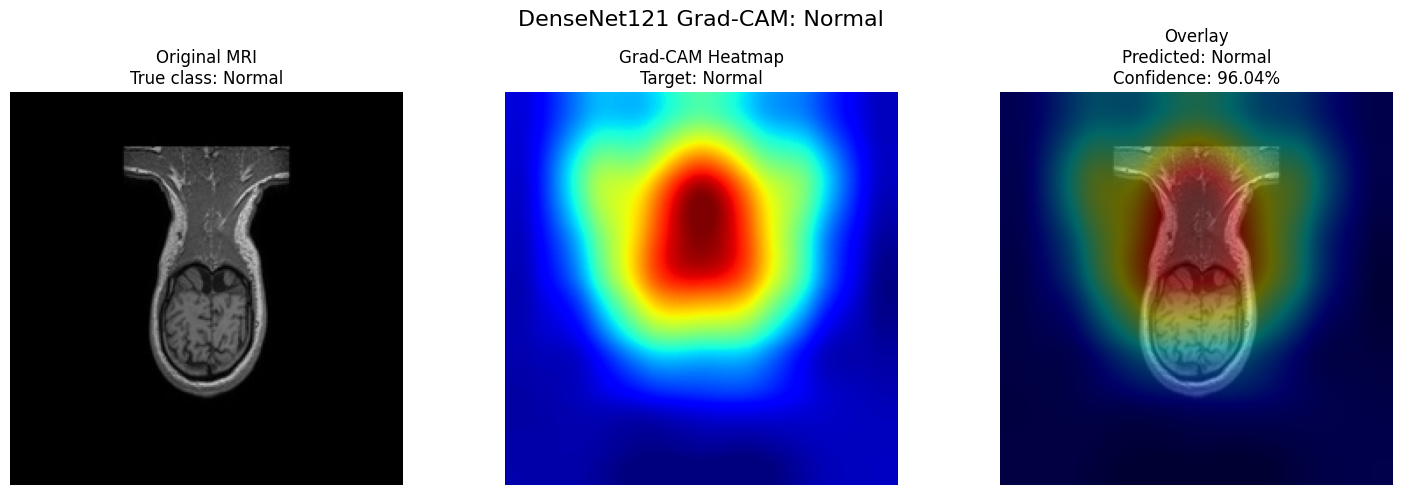

Saved: /content/gradcam_results/Normal/gradcam_normal.png

Generating Grad-CAM for Stroke...


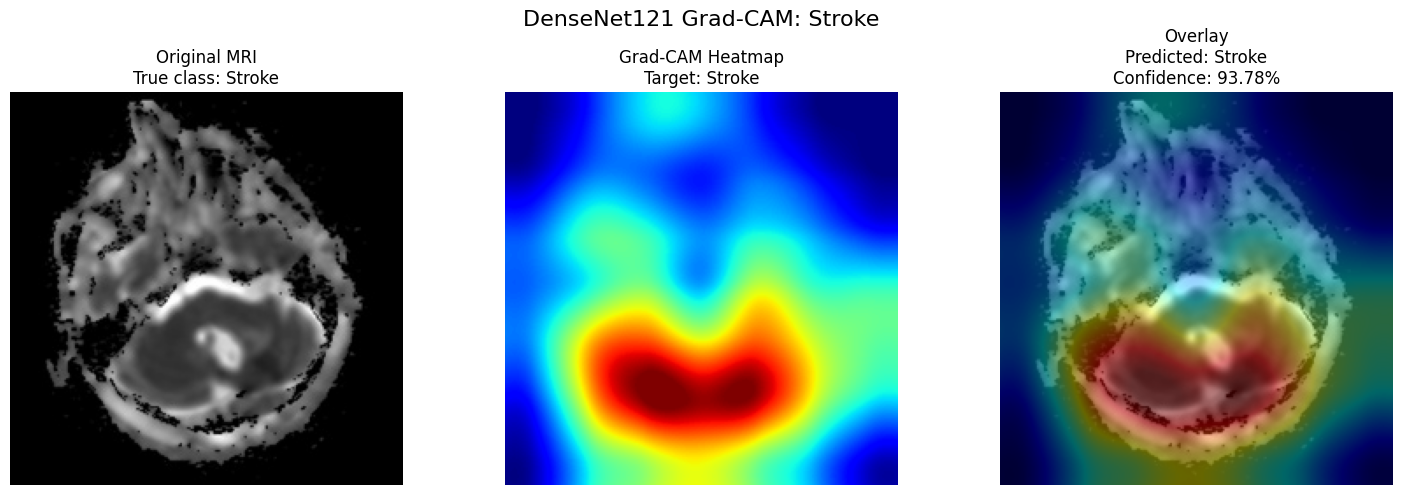

Saved: /content/gradcam_results/Stroke/gradcam_stroke.png

Generating Grad-CAM for Tumor...


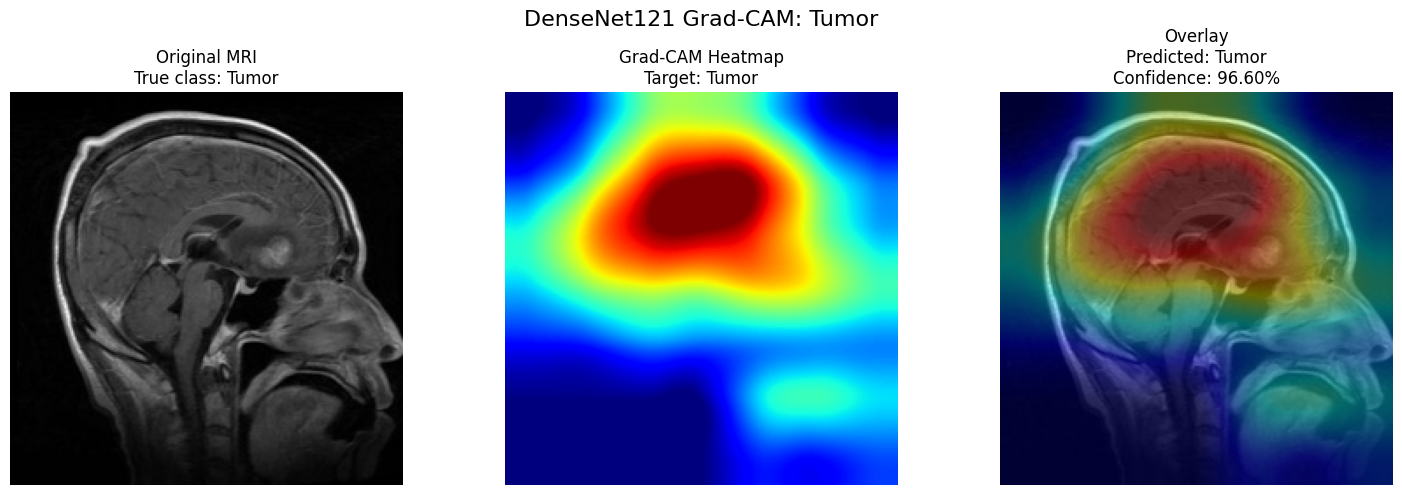

Saved: /content/gradcam_results/Tumor/gradcam_tumor.png

ALL THREE GRAD-CAM VISUALIZATIONS COMPLETED
Results folder: /content/gradcam_results


In [22]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

from PIL import Image
from tensorflow.keras.applications.densenet import preprocess_input

# ==========================================================
# 1. CONFIGURATION
# ==========================================================

IMG_SIZE = (224, 224)

class_names = ["Normal", "Stroke", "Tumor"]

# Folder for saving the Grad-CAM results
gradcam_dir = "/content/gradcam_results"

os.makedirs(gradcam_dir, exist_ok=True)

for class_name in class_names:
    os.makedirs(
        os.path.join(gradcam_dir, class_name),
        exist_ok=True
    )

# ==========================================================
# 2. ACCESS THE MODEL LAYERS
# ==========================================================

base_model = model.get_layer("densenet121")

pool_layer = model.get_layer("global_average_pooling2d")
dropout_layer = model.get_layer("dropout")
output_layer = model.get_layer("classification_output")

print("Grad-CAM layers prepared successfully.")

# ==========================================================
# 3. DEFINE THE GRAD-CAM FUNCTION
# ==========================================================

def generate_gradcam(image_array, target_class_index):

    # Convert the image to a TensorFlow tensor
    input_tensor = tf.convert_to_tensor(
        image_array,
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        # Extract the final spatial feature maps
        feature_maps = base_model(
            input_tensor,
            training=False
        )

        # Watch the feature maps so gradients can be calculated
        tape.watch(feature_maps)

        # Reproduce the model's classification head
        x = pool_layer(feature_maps)
        x = dropout_layer(x, training=False)
        predictions = output_layer(x)

        # Select the score for the target class
        target_score = predictions[:, target_class_index]

    # Calculate gradients of the target score
    # with respect to the feature maps
    gradients = tape.gradient(
        target_score,
        feature_maps
    )

    if gradients is None:
        raise ValueError(
            "Gradients could not be calculated. "
            "Check the model architecture."
        )

    # Average gradients across the spatial dimensions
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    # Weight the feature maps using the gradients
    cam = tf.reduce_sum(
        feature_maps[0] * weights[0][tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    # Keep positive contributions
    cam = tf.nn.relu(cam)

    # Convert to NumPy
    cam = cam.numpy()

    # Normalize the heatmap between 0 and 1
    cam_min = cam.min()
    cam_max = cam.max()

    if cam_max > cam_min:
        cam = (cam - cam_min) / (cam_max - cam_min)
    else:
        cam = np.zeros_like(cam)

    return cam


# ==========================================================
# 4. PREPARE THE TEST IMAGES
# ==========================================================

test_data.reset()

# Obtain predictions for the test dataset
test_probabilities = model.predict(
    test_data,
    verbose=1
)

test_predictions = np.argmax(
    test_probabilities,
    axis=1
)

true_labels = test_data.classes
image_paths = test_data.filepaths

print("\nTest predictions completed.")
print("Images available:", len(image_paths))

# ==========================================================
# 5. SELECT ONE IMAGE FOR EACH CLASS
# ==========================================================

selected_indices = {}

for class_index, class_name in enumerate(class_names):

    # Find test images belonging to this true class
    class_indices = np.where(
        true_labels == class_index
    )[0]

    # Prefer a correctly classified example
    correct_indices = [
        i for i in class_indices
        if test_predictions[i] == class_index
    ]

    if len(correct_indices) > 0:
        selected_index = correct_indices[0]
        print(
            f"{class_name}: selected a correctly "
            "classified test image."
        )

    elif len(class_indices) > 0:
        selected_index = class_indices[0]
        print(
            f"{class_name}: no correctly classified "
            "example found; using the first available "
            "test image from this class."
        )

    else:
        print(f"No test images found for {class_name}.")
        continue

    selected_indices[class_name] = selected_index


# ==========================================================
# 6. GENERATE AND DISPLAY THE HEATMAPS
# ==========================================================

for class_name, image_index in selected_indices.items():

    print(f"\nGenerating Grad-CAM for {class_name}...")

    # Get the original image path
    image_path = image_paths[image_index]

    # Load the original MRI image
    original_image = Image.open(
        image_path
    ).convert("RGB")

    original_image = original_image.resize(
        IMG_SIZE
    )

    original_array = np.array(
        original_image
    )

    # Preprocess the image for DenseNet121
    image_array = preprocess_input(
        original_array.astype(np.float32).copy()
    )

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # Obtain prediction information
    probabilities = test_probabilities[image_index]

    predicted_index = int(
        test_predictions[image_index]
    )

    predicted_class = class_names[predicted_index]

    true_class = class_names[
        true_labels[image_index]
    ]

    confidence = float(
        probabilities[predicted_index]
    ) * 100

    # Generate Grad-CAM for the TRUE class.
    # This allows us to examine evidence relevant
    # to the class the MRI actually belongs to.
    target_class_index = class_names.index(
        class_name
    )

    heatmap = generate_gradcam(
        image_array,
        target_class_index
    )

    # Resize heatmap to match the original image
    heatmap_resized = cv2.resize(
        heatmap,
        (original_array.shape[1], original_array.shape[0]),
        interpolation=cv2.INTER_CUBIC
    )

    # Normalize again after interpolation
    heatmap_resized = np.clip(
        heatmap_resized,
        0,
        1
    )

    # Convert heatmap into a colour image
    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    heatmap_colored = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    # OpenCV uses BGR; convert to RGB
    heatmap_colored = cv2.cvtColor(
        heatmap_colored,
        cv2.COLOR_BGR2RGB
    )

    # Overlay heatmap on the original MRI image
    overlay = cv2.addWeighted(
        original_array,
        0.60,
        heatmap_colored,
        0.40,
        0
    )

    # ======================================================
    # 7. DISPLAY THE THREE IMAGES
    # ======================================================

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    axes[0].imshow(original_array, cmap="gray")
    axes[0].set_title(
        f"Original MRI\nTrue class: {true_class}"
    )
    axes[0].axis("off")

    axes[1].imshow(
        heatmap_resized,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[1].set_title(
        f"Grad-CAM Heatmap\nTarget: {class_name}"
    )
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title(
        f"Overlay\nPredicted: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    axes[2].axis("off")

    plt.suptitle(
        f"DenseNet121 Grad-CAM: {class_name}",
        fontsize=16
    )

    plt.tight_layout()

    # Save each class result
    output_path = os.path.join(
        gradcam_dir,
        class_name,
        f"gradcam_{class_name.lower()}.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)

print("\n" + "=" * 60)
print("ALL THREE GRAD-CAM VISUALIZATIONS COMPLETED")
print("=" * 60)
print("Results folder:", gradcam_dir)

In [23]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.densenet import preprocess_input
from IPython.display import display


# LOAD THE FINE-TUNED DENSENET121 MODEL

MODEL_PATH = (
    "/content/densenet_finetuned/"
    "best_densenet121_finetuned.keras"
)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"Model not found at: {MODEL_PATH}\n"
        "Check that the fine-tuned model file exists in Colab."
    )

model = load_model(MODEL_PATH, compile=False)

print("Fine-tuned DenseNet121 loaded successfully!")
print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)


# FIND THE TEST DATASET FOLDER

SPLIT_ROOT = Path("/content/MRI_Split_Dataset")

test_candidates = [
    p for p in SPLIT_ROOT.iterdir()
    if p.is_dir() and p.name.lower() in ["test", "testing"]
] if SPLIT_ROOT.exists() else []

if not test_candidates:
    raise FileNotFoundError(
        "Could not find a Test or Testing folder inside "
        "/content/MRI_Split_Dataset. Check the folder names."
    )

TEST_DIR = str(test_candidates[0])

CLASS_NAMES = ["Normal", "Stroke", "Tumor"]

print("\nTest folder:", TEST_DIR)

#  LOAD TEST IMAGES IN THE CORRECT CLASS ORDER

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Keep the original images for displaying overlays.
# Apply DenseNet preprocessing only to model inputs.
test_ds = raw_test_ds.map(
    lambda images, labels: (
        preprocess_input(tf.cast(images, tf.float32)),
        labels
    ),
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.prefetch(AUTOTUNE)

print("\nClass mapping:", {
    name: index for index, name in enumerate(CLASS_NAMES)
})
print("Test images:", len(raw_test_ds.file_paths))

# PREDICT THE TEST SET

probabilities = model.predict(test_ds, verbose=1)

y_true = np.concatenate([
    labels.numpy() for _, labels in raw_test_ds
])

y_pred = np.argmax(probabilities, axis=1)

print("\nTest predictions completed.")
print("Number of predictions:", len(y_pred))

Fine-tuned DenseNet121 loaded successfully!
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 3)

Test folder: /content/MRI_Split_Dataset/test
Found 497 files belonging to 3 classes.

Class mapping: {'Normal': 0, 'Stroke': 1, 'Tumor': 2}
Test images: 497
16/16 ━━━━━━━━━━━━━━━━━━━━ 25s 889ms/step

Test predictions completed.
Number of predictions: 497


In [24]:
def calculate_gradcam(image_tensor, class_index):

    # Record operations so TensorFlow can calculate gradients.
    with tf.GradientTape() as tape:

        # Extract convolutional feature maps.
        feature_maps = grad_backbone(
            image_tensor,
            training=False
        )

        tape.watch(feature_maps)

        # Pass feature maps through the trained classification head.
        pooled = gap_layer(feature_maps)
        dropped = dropout_layer(pooled, training=False)
        class_scores = classifier_layer(dropped)

        # Explain the predicted class.
        score = class_scores[:, class_index]

    # Calculate gradients of the class score with respect to feature maps.
    gradients = tape.gradient(score, feature_maps)

    if gradients is None:
        raise ValueError(
            "Gradients could not be calculated. "
            "Check the target layer and model architecture."
        )

    # Calculate the importance weights for each feature map.
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2),
        keepdims=True
    )

    # Combine feature maps using their importance weights.
    heatmap = tf.reduce_sum(
        weights * feature_maps,
        axis=-1
    )

    # Keep positive contributions and normalise.
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap[0]

    max_value = tf.reduce_max(heatmap)
    heatmap = tf.math.divide_no_nan(
        heatmap,
        max_value
    )

    # Convert to a NumPy array outside graph mode.
    return heatmap.numpy()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fine-tuned DenseNet121 loaded.
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)
Test folder: /content/MRI_Split_Dataset/test
Found 497 files belonging to 3 classes.
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 852ms/step
Test images loaded: 497
Class mapping: {'Normal': 0, 'Stroke': 1, 'Tumor': 2}
Grad-CAM layer: conv4_block24_concat
Feature map shape: (None, 14, 14, 1024)
Normal: selected 3 images
Stroke: selected 3 images
Tumor: selected 3 images


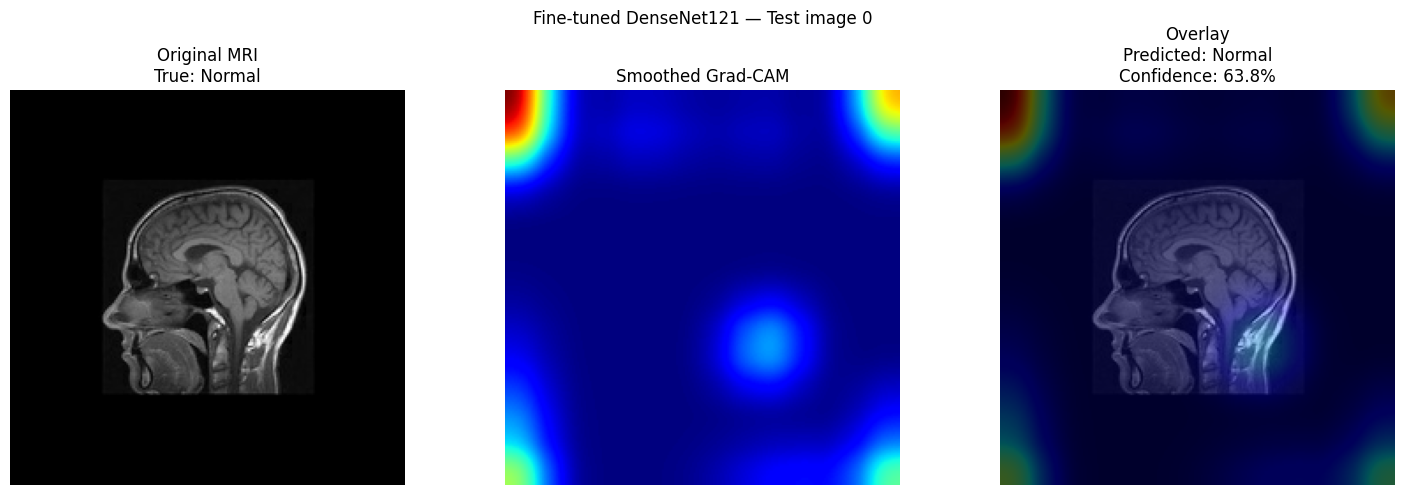

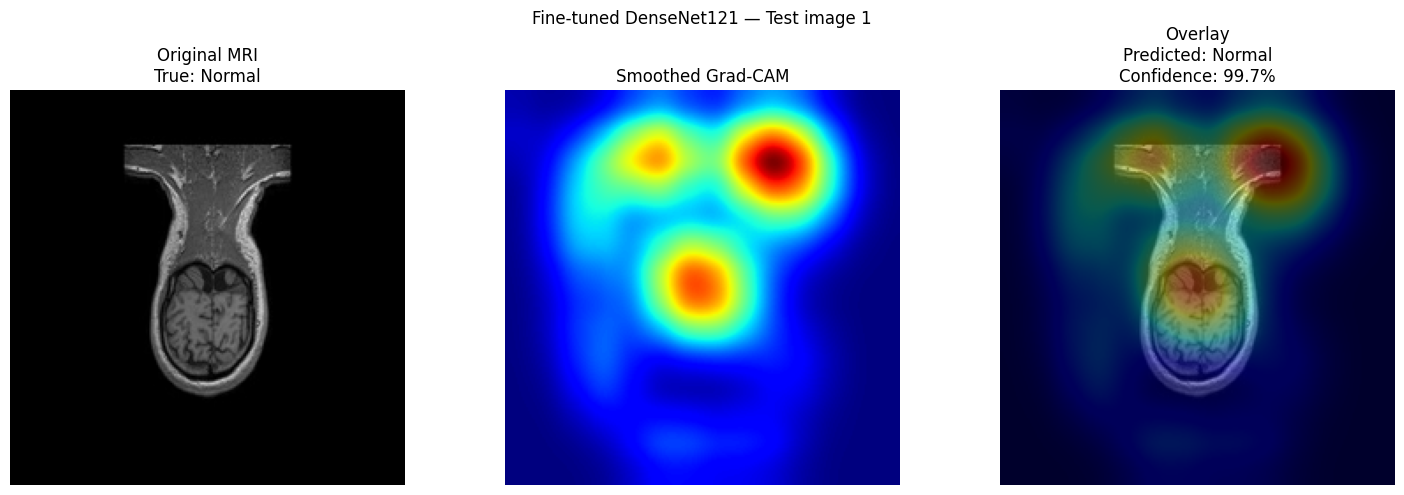

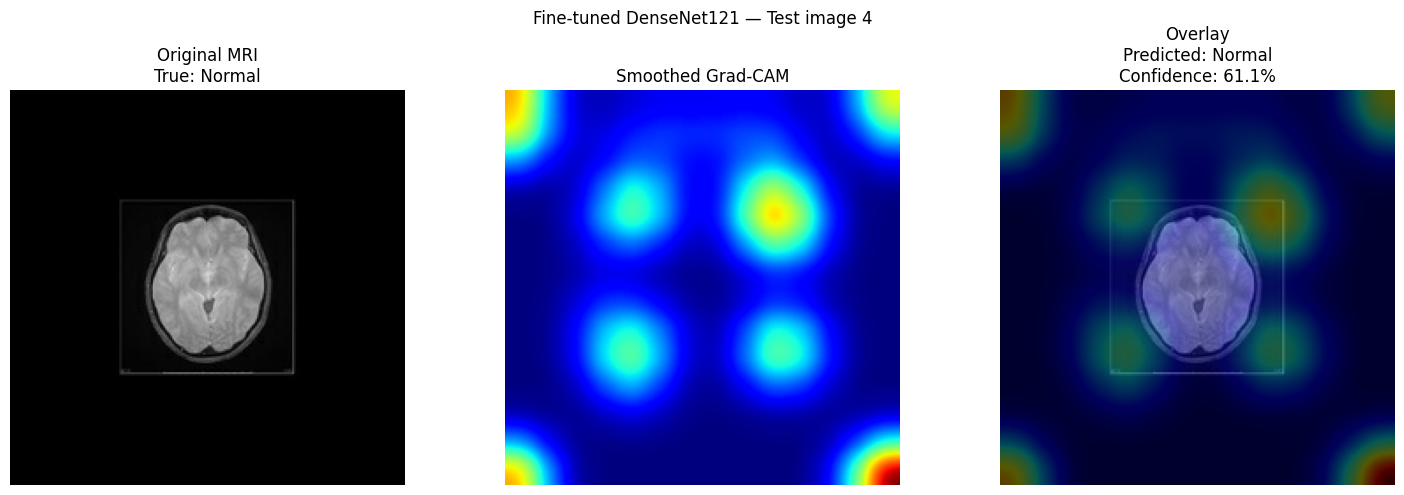

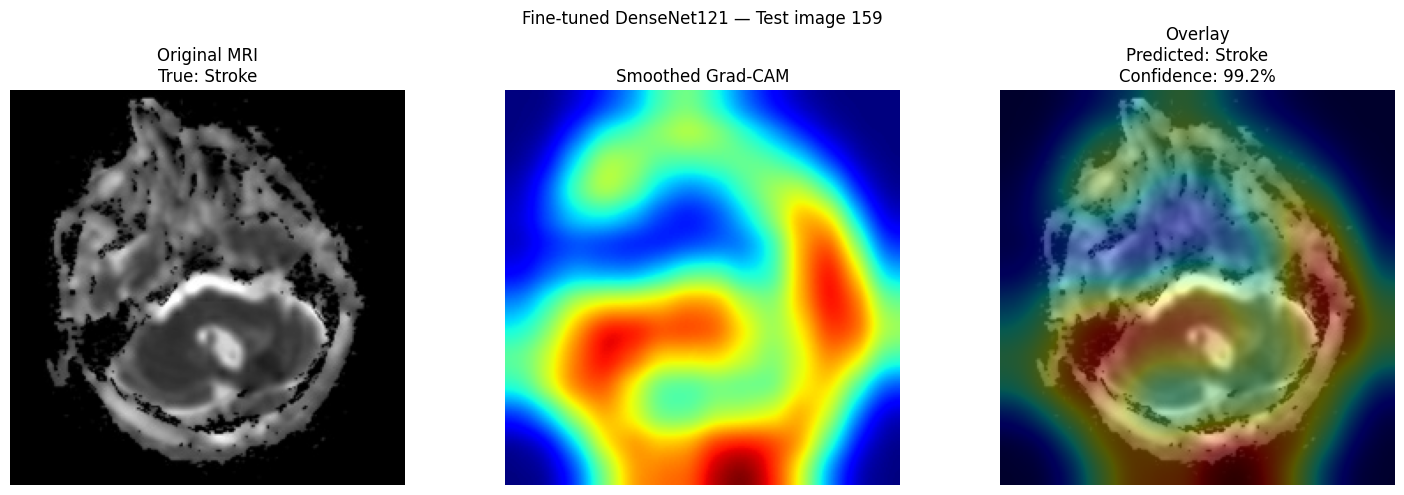

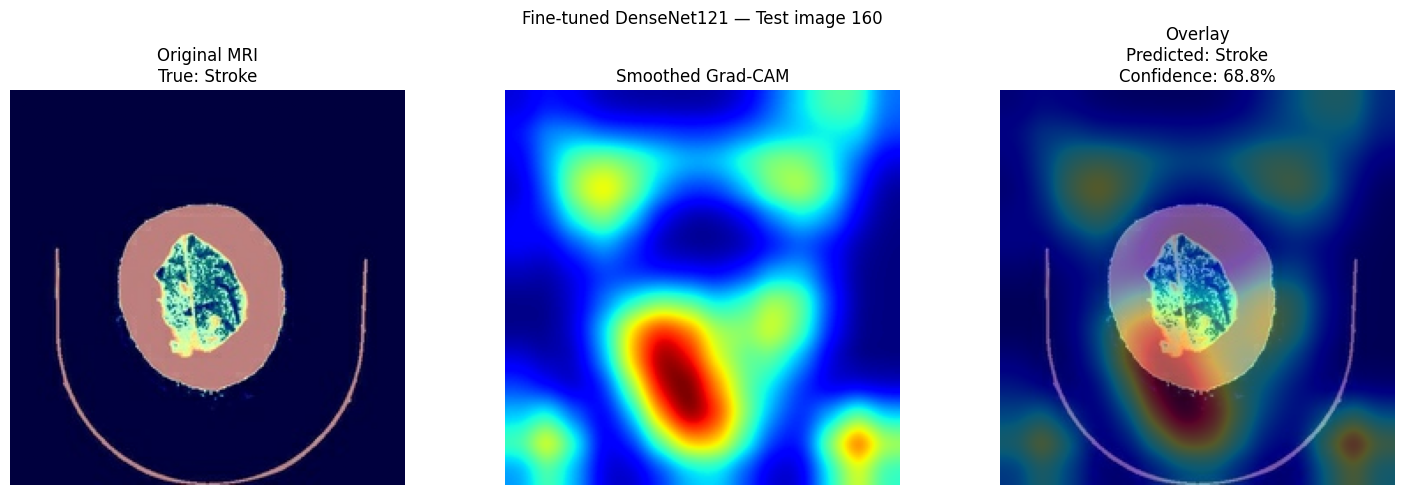

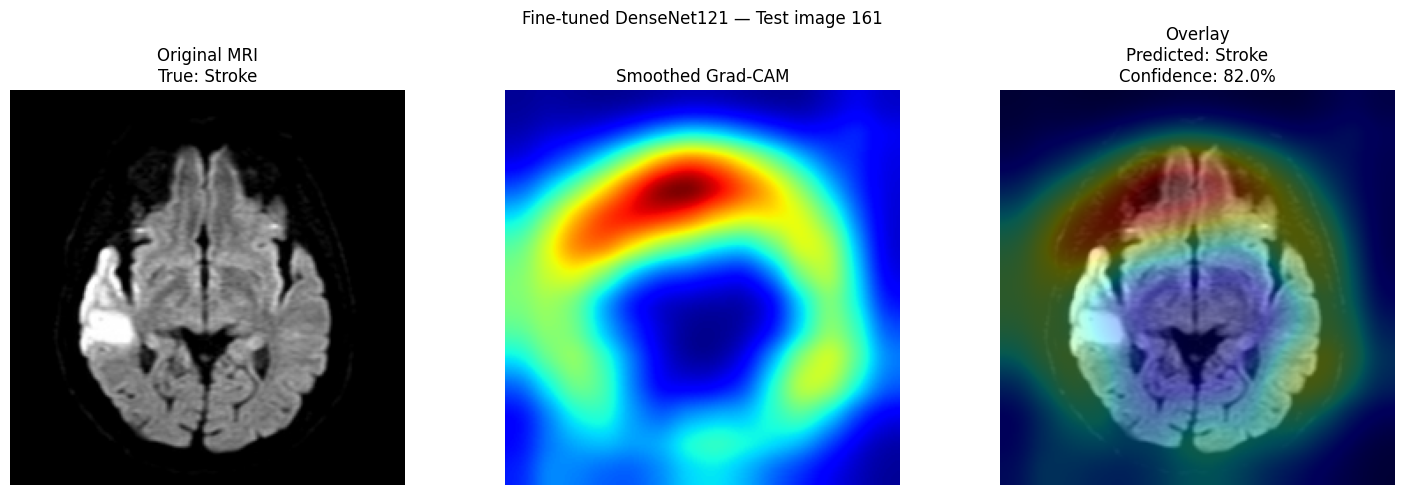

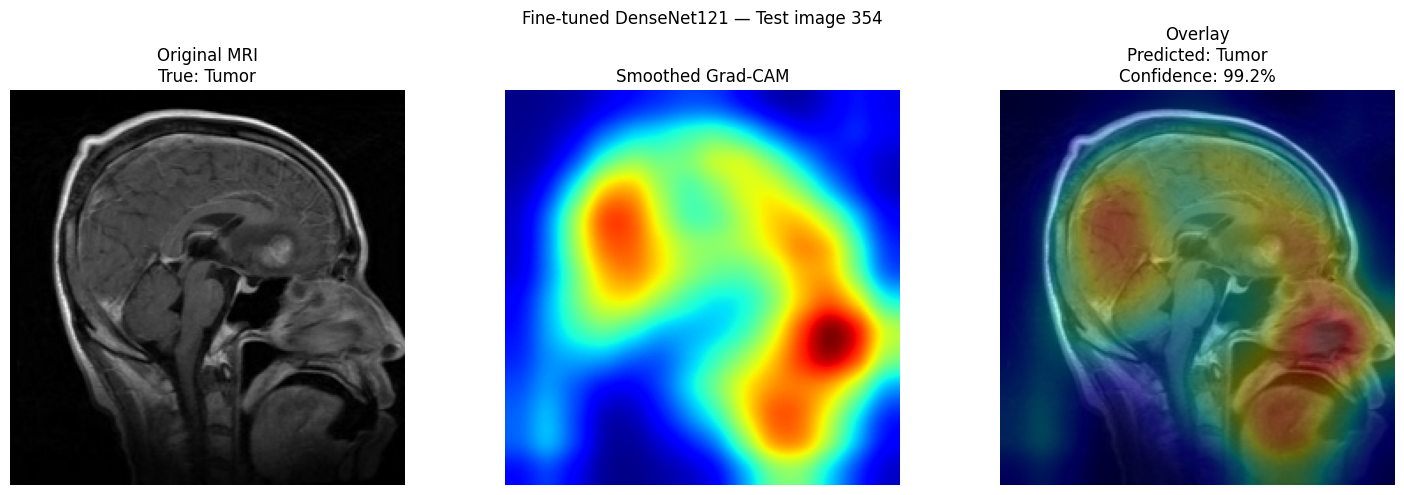

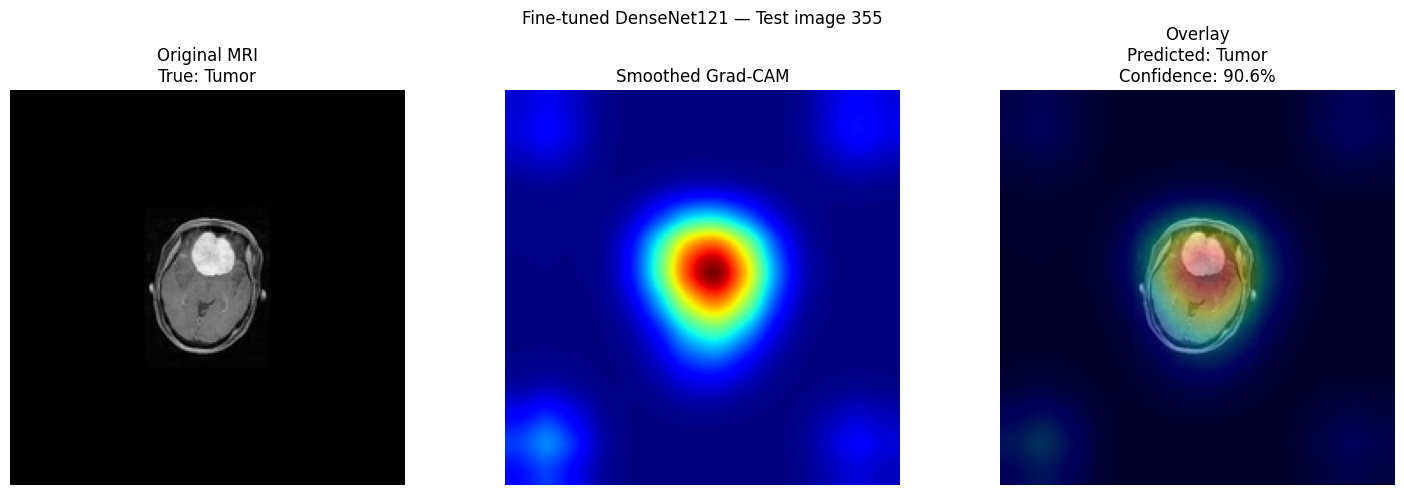

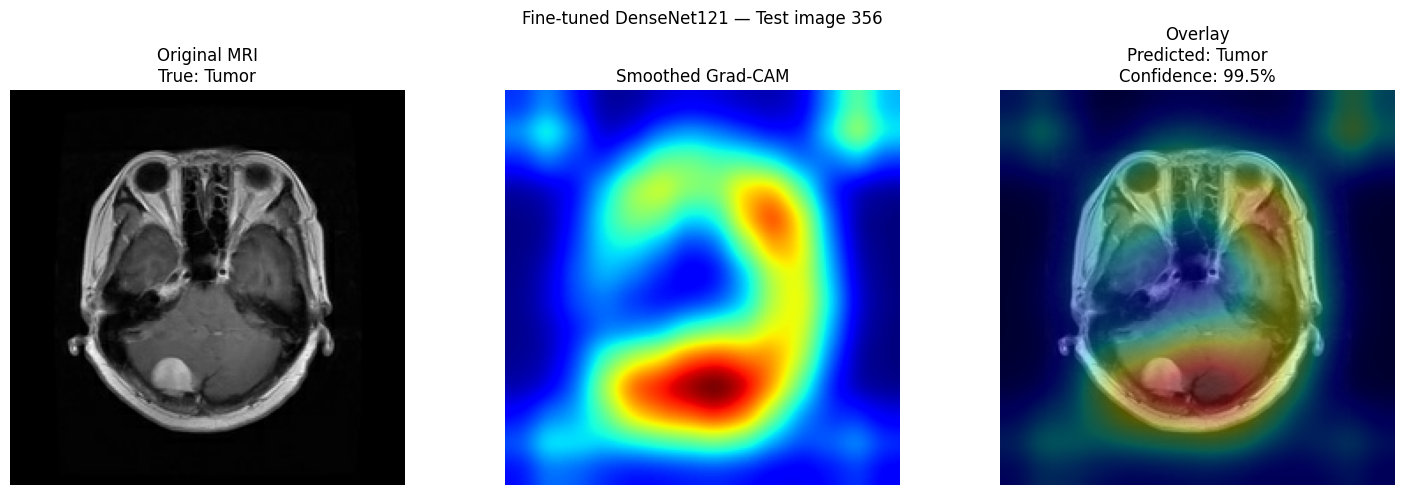


Grad-CAM generation completed.
Saved to Google Drive: /content/drive/MyDrive/MRI_Classification_Project/gradcam_finetuned
Summary CSV: /content/drive/MyDrive/MRI_Classification_Project/gradcam_finetuned/gradcam_summary.csv


,Test index,True class,Predicted class,Confidence,Correct,Original image,Heatmap,Overlay
0,0,Normal,Normal,0.6380,True,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...
1,1,Normal,Normal,0.9971,True,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...
2,4,Normal,Normal,0.6106,True,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...
3,159,Stroke,Stroke,0.9923,True,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...
4,160,Stroke,Stroke,0.6877,True,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...
5,161,Stroke,Stroke,0.8200,True,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...
6,354,Tumor,Tumor,0.9920,True,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...
7,355,Tumor,Tumor,0.9065,True,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...
8,356,Tumor,Tumor,0.9948,True,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...,/content/drive/MyDrive/MRI_Classification_Proj...


In [25]:
#FINE-TUNED DENSENET121 GRAD-CAM

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.ndimage import gaussian_filter
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.densenet import preprocess_input
from IPython.display import display
from google.colab import drive


# MOUNT GOOGLE DRIVE

drive.mount("/content/drive")

# LOAD YOUR FINE-TUNED MODEL

MODEL_PATH = (
    "/content/densenet_finetuned/"
    "best_densenet121_finetuned.keras"
)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"Model not found: {MODEL_PATH}\n"
        "Check that your fine-tuned model exists in Colab."
    )

model = load_model(MODEL_PATH, compile=False)

print("Fine-tuned DenseNet121 loaded.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

#  FIND THE TEST FOLDER

SPLIT_ROOT = Path("/content/MRI_Split_Dataset")

if not SPLIT_ROOT.exists():
    raise FileNotFoundError(
        "Dataset folder not found: /content/MRI_Split_Dataset"
    )

test_candidates = [
    p for p in SPLIT_ROOT.iterdir()
    if p.is_dir() and p.name.lower() in ["test", "testing"]
]

if not test_candidates:
    raise FileNotFoundError(
        "Could not find a Test folder inside MRI_Split_Dataset."
    )

TEST_DIR = str(test_candidates[0])

CLASS_NAMES = ["Normal", "Stroke", "Tumor"]
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

print("Test folder:", TEST_DIR)

# LOAD TEST IMAGES

raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Keep raw images for display and use DenseNet preprocessing
# for predictions.
test_ds = raw_test_ds.map(
    lambda images, labels: (
        preprocess_input(tf.cast(images, tf.float32)),
        labels
    )
).prefetch(tf.data.AUTOTUNE)

y_true = np.concatenate([
    labels.numpy() for _, labels in raw_test_ds
])

probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

print("Test images loaded:", len(y_true))
print("Class mapping:", {
    name: i for i, name in enumerate(CLASS_NAMES)
})

# SELECT A HIGHER-RESOLUTION CONVOLUTIONAL LAYER

backbone = model.get_layer("densenet121")

# This layer normally produces a 14 x 14 feature map,
# instead of the final 7 x 7 map.
target_layer = backbone.get_layer("conv4_block24_concat")

print("Grad-CAM layer:", target_layer.name)
print("Feature map shape:", target_layer.output.shape)

# Extract the selected intermediate feature maps.
feature_extractor = tf.keras.Model(
    inputs=backbone.input,
    outputs=target_layer.output
)

# Continue processing from the selected layer to the
# final DenseNet121 feature maps.
tail_model = tf.keras.Model(
    inputs=target_layer.output,
    outputs=backbone.output
)

# Reuse the already-trained classification head.
gap_layer = model.get_layer("global_average_pooling2d")
dropout_layer = model.get_layer("dropout")
classifier_layer = model.get_layer("classification_output")


# GRAD-CAM FUNCTION

def calculate_gradcam(image_tensor, class_index):

    with tf.GradientTape() as tape:

        # Intermediate convolutional features.
        feature_maps = feature_extractor(
            image_tensor,
            training=False
        )

        tape.watch(feature_maps)

        # Continue through the rest of DenseNet121.
        final_features = tail_model(
            feature_maps,
            training=False
        )

        # Apply the original trained classification head.
        pooled = gap_layer(final_features)
        dropped = dropout_layer(pooled, training=False)
        scores = classifier_layer(dropped)

        # Explain the selected class score.
        score = scores[:, int(class_index)]

    gradients = tape.gradient(score, feature_maps)

    if gradients is None:
        raise ValueError(
            "Gradients could not be calculated. "
            "Check the selected convolutional layer."
        )

    # Average gradients over spatial dimensions.
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2),
        keepdims=True
    )

    # Weighted sum of feature maps.
    heatmap = tf.reduce_sum(
        weights * feature_maps,
        axis=-1
    )

    # Keep positive contributions.
    heatmap = tf.nn.relu(heatmap)[0].numpy()

    # Normalise the original heatmap.
    max_value = float(np.max(heatmap))

    if max_value > 0:
        heatmap = heatmap / max_value
    else:
        return np.zeros(IMAGE_SIZE, dtype=np.float32)

    # Smooth the low-resolution heatmap to reduce harsh squares.
    heatmap = gaussian_filter(heatmap, sigma=1.0)

    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    # Enlarge using bicubic interpolation.
    heatmap_tensor = tf.convert_to_tensor(
        heatmap[None, ..., None],
        dtype=tf.float32
    )

    heatmap = tf.image.resize(
        heatmap_tensor,
        IMAGE_SIZE,
        method="bicubic"
    )[0, ..., 0].numpy()

    # Remove negative interpolation artefacts and normalise.
    heatmap = np.maximum(heatmap, 0)

    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    return heatmap

#  SELECT TEST IMAGES

IMAGES_PER_CLASS = 3
selected_indices = []

for class_id, class_name in enumerate(CLASS_NAMES):

    indices = np.where(y_true == class_id)[0]

    correct = [i for i in indices if y_pred[i] == class_id]
    incorrect = [i for i in indices if y_pred[i] != class_id]

    # Prefer correct predictions, but include mistakes if needed.
    chosen = (correct + incorrect)[:IMAGES_PER_CLASS]
    selected_indices.extend(chosen)

    print(f"{class_name}: selected {len(chosen)} images")

selected_indices = sorted(set(selected_indices))
selected_set = set(selected_indices)

# Retrieve the matching original images.
selected_images = {}

for batch_number, (images, labels) in enumerate(raw_test_ds):
    start = batch_number * BATCH_SIZE

    for local_i in range(images.shape[0]):
        global_i = start + local_i

        if global_i in selected_set:
            selected_images[global_i] = images[local_i].numpy()


# SAVE RESULTS DIRECTLY TO GOOGLE DRIVE

OUTPUT_DIR = (
    "/content/drive/MyDrive/MRI_Classification_Project/"
    "gradcam_finetuned"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

results = []

# GENERATE AND DISPLAY THE GRAD-CAM VISUALISATIONS

for index in selected_indices:

    original_image = selected_images[index]

    true_id = int(y_true[index])
    predicted_id = int(y_pred[index])

    true_class = CLASS_NAMES[true_id]
    predicted_class = CLASS_NAMES[predicted_id]
    confidence = float(probabilities[index, predicted_id])

    # Apply the exact preprocessing used for model training.
    image_tensor = preprocess_input(
        tf.convert_to_tensor(
            original_image[None, ...],
            dtype=tf.float32
        )
    )

    # Explain the predicted class.
    heatmap = calculate_gradcam(
        image_tensor,
        predicted_id
    )

    # Convert the MRI to display range.
    display_image = np.clip(
        original_image / 255.0,
        0,
        1
    )

    # Colour the heatmap and blend with the original MRI.
    coloured_heatmap = plt.get_cmap("jet")(
        heatmap
    )[..., :3]

    overlay = np.clip(
        0.65 * display_image +
        0.35 * coloured_heatmap,
        0,
        1
    )

    # Save each image under its true class.
    class_dir = os.path.join(OUTPUT_DIR, true_class)
    os.makedirs(class_dir, exist_ok=True)

    filename = f"test_image_{index:04d}"

    original_path = os.path.join(
        class_dir, f"{filename}_original.png"
    )
    heatmap_path = os.path.join(
        class_dir, f"{filename}_heatmap.png"
    )
    overlay_path = os.path.join(
        class_dir, f"{filename}_overlay.png"
    )

    plt.imsave(original_path, display_image)
    plt.imsave(heatmap_path, heatmap, cmap="jet", vmin=0, vmax=1)
    plt.imsave(overlay_path, overlay)

    # Display original, heatmap and overlay.
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(display_image, cmap="gray")
    axes[0].set_title(f"Original MRI\nTrue: {true_class}")

    axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title("Smoothed Grad-CAM")

    axes[2].imshow(overlay)
    axes[2].set_title(
        f"Overlay\nPredicted: {predicted_class}\n"
        f"Confidence: {confidence:.1%}"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"Fine-tuned DenseNet121 — Test image {index}"
    )
    plt.tight_layout()
    display(fig)
    plt.close(fig)

    results.append({
        "Test index": index,
        "True class": true_class,
        "Predicted class": predicted_class,
        "Confidence": round(confidence, 4),
        "Correct": true_id == predicted_id,
        "Original image": original_path,
        "Heatmap": heatmap_path,
        "Overlay": overlay_path
    })


# SAVE THE SUMMARY TABLE

results_df = pd.DataFrame(results)

csv_path = os.path.join(
    OUTPUT_DIR,
    "gradcam_summary.csv"
)

results_df.to_csv(csv_path, index=False)

print("\nGrad-CAM generation completed.")
print("Saved to Google Drive:", OUTPUT_DIR)
print("Summary CSV:", csv_path)

display(results_df)


Fine-tuned DenseNet121 loaded successfully.
Test folder: /content/MRI_Split_Dataset/test
Found 497 files belonging to 3 classes.
16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 851ms/step

Number of test images: 497
Prediction shape: (497, 3)
Class mapping: {'Normal': 0, 'Stroke': 1, 'Tumor': 2}
Normal AUC: 0.9456
Stroke AUC: 0.9677
Tumor AUC: 0.9792

Micro-average AUC: 0.9645
Macro-average AUC: 0.9653


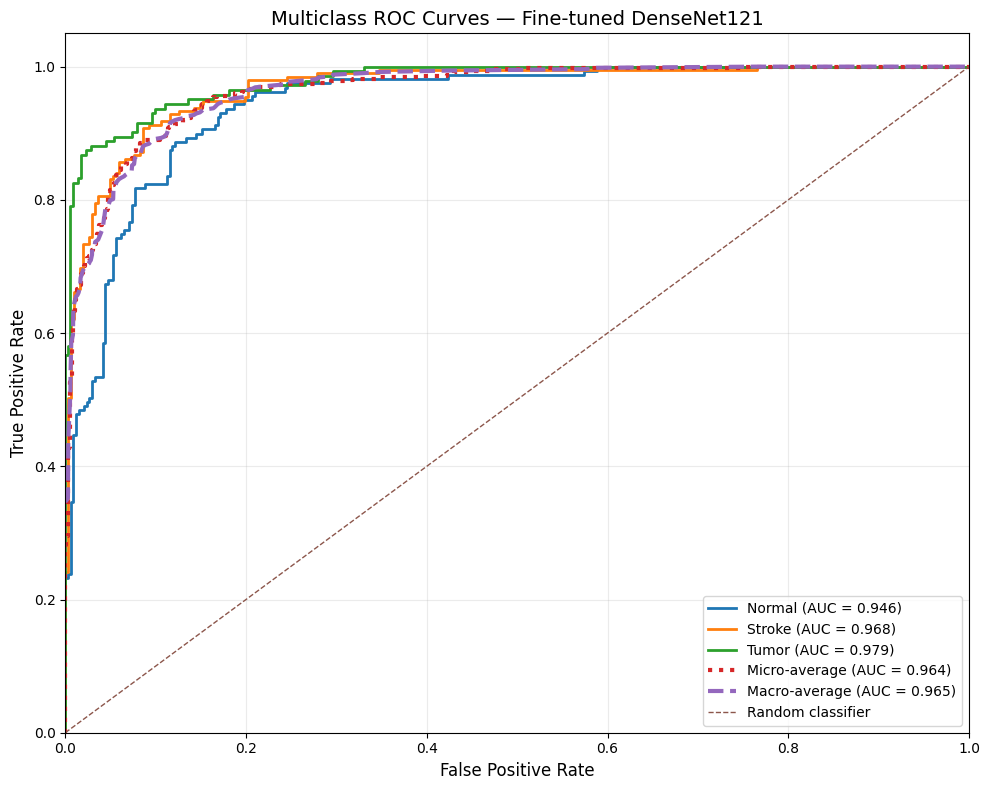


ROC analysis completed successfully.
ROC graph: /content/roc_finetuned_densenet/finetuned_densenet_multiclass_roc.png
AUC summary: /content/roc_finetuned_densenet/roc_auc_summary.csv


,Class/Average,AUC
0,Normal,0.9456
1,Stroke,0.9677
2,Tumor,0.9792
3,Micro-average,0.9645
4,Macro-average,0.9653



Results also saved to Google Drive:
/content/drive/MyDrive/MRI_Classification_Project/roc_finetuned_densenet


In [26]:
# MULTICLASS ROC CURVE — FINE-TUNED DENSENET121

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.densenet import preprocess_input
from IPython.display import display

# LOAD THE FINE-TUNED MODEL

MODEL_PATH = (
    "/content/densenet_finetuned/"
    "best_densenet121_finetuned.keras"
)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"Model not found: {MODEL_PATH}\n"
        "Check that your fine-tuned model exists in Colab."
    )

model = load_model(MODEL_PATH, compile=False)

print("Fine-tuned DenseNet121 loaded successfully.")

# FIND THE TEST DATASET

SPLIT_ROOT = Path("/content/MRI_Split_Dataset")

if not SPLIT_ROOT.exists():
    raise FileNotFoundError(
        "Dataset folder not found: /content/MRI_Split_Dataset"
    )

test_candidates = [
    p for p in SPLIT_ROOT.iterdir()
    if p.is_dir() and p.name.lower() in ["test", "testing"]
]

if not test_candidates:
    raise FileNotFoundError(
        "Could not find the Test folder inside MRI_Split_Dataset."
    )

TEST_DIR = str(test_candidates[0])

CLASS_NAMES = ["Normal", "Stroke", "Tumor"]
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

print("Test folder:", TEST_DIR)

#LOAD TEST IMAGES

raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Apply the same DenseNet preprocessing used during training.
test_ds = raw_test_ds.map(
    lambda images, labels: (
        preprocess_input(tf.cast(images, tf.float32)),
        labels
    ),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)


# GET TRUE LABELS AND PREDICTED PROBABILITIES

y_true = np.concatenate([
    labels.numpy()
    for _, labels in raw_test_ds
])

y_prob = model.predict(test_ds, verbose=1)

if y_prob.shape[1] != len(CLASS_NAMES):
    raise ValueError(
        f"Expected 3 class probabilities, but got {y_prob.shape}"
    )

print("\nNumber of test images:", len(y_true))
print("Prediction shape:", y_prob.shape)
print("Class mapping:", {
    name: i for i, name in enumerate(CLASS_NAMES)
})

# CONVERT LABELS FOR MULTICLASS ROC ANALYSIS

n_classes = len(CLASS_NAMES)

y_true_binary = label_binarize(
    y_true,
    classes=np.arange(n_classes)
)

# CALCULATE ROC CURVES AND AUC SCORES

fpr = {}
tpr = {}
roc_auc = {}

for i, class_name in enumerate(CLASS_NAMES):

    fpr[i], tpr[i], _ = roc_curve(
        y_true_binary[:, i],
        y_prob[:, i]
    )

    roc_auc[i] = auc(fpr[i], tpr[i])

    print(f"{class_name} AUC: {roc_auc[i]:.4f}")

# Micro-average ROC curve
fpr["micro"], tpr["micro"], _ = roc_curve(
    y_true_binary.ravel(),
    y_prob.ravel()
)

roc_auc["micro"] = auc(
    fpr["micro"],
    tpr["micro"]
)

# Macro-average ROC curve
all_fpr = np.unique(
    np.concatenate([
        fpr[i] for i in range(n_classes)
    ])
)

mean_tpr = np.zeros_like(all_fpr)

for i in range(n_classes):
    mean_tpr += np.interp(
        all_fpr,
        fpr[i],
        tpr[i]
    )

mean_tpr /= n_classes

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr

roc_auc["macro"] = auc(
    fpr["macro"],
    tpr["macro"]
)

print(f"\nMicro-average AUC: {roc_auc['micro']:.4f}")
print(f"Macro-average AUC: {roc_auc['macro']:.4f}")


# PLOT ALL ROC CURVES

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(CLASS_NAMES):
    plt.plot(
        fpr[i],
        tpr[i],
        linewidth=2,
        label=f"{class_name} (AUC = {roc_auc[i]:.3f})"
    )

plt.plot(
    fpr["micro"],
    tpr["micro"],
    linestyle=":",
    linewidth=3,
    label=f"Micro-average (AUC = {roc_auc['micro']:.3f})"
)

plt.plot(
    fpr["macro"],
    tpr["macro"],
    linestyle="--",
    linewidth=3,
    label=f"Macro-average (AUC = {roc_auc['macro']:.3f})"
)

# Random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Random classifier"
)

plt.xlim([0, 1])
plt.ylim([0, 1.05])

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title(
    "Multiclass ROC Curves — Fine-tuned DenseNet121",
    fontsize=14
)

plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()

# SAVE THE ROC GRAPH AND AUC SUMMARY

OUTPUT_DIR = "/content/roc_finetuned_densenet"

os.makedirs(OUTPUT_DIR, exist_ok=True)

graph_path = os.path.join(
    OUTPUT_DIR,
    "finetuned_densenet_multiclass_roc.png"
)

plt.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Create the AUC summary table
auc_rows = [
    {
        "Class/Average": CLASS_NAMES[i],
        "AUC": round(float(roc_auc[i]), 4)
    }
    for i in range(n_classes)
]

auc_rows.extend([
    {
        "Class/Average": "Micro-average",
        "AUC": round(float(roc_auc["micro"]), 4)
    },
    {
        "Class/Average": "Macro-average",
        "AUC": round(float(roc_auc["macro"]), 4)
    }
])

auc_df = pd.DataFrame(auc_rows)

csv_path = os.path.join(
    OUTPUT_DIR,
    "roc_auc_summary.csv"
)

auc_df.to_csv(csv_path, index=False)

print("\nROC analysis completed successfully.")
print("ROC graph:", graph_path)
print("AUC summary:", csv_path)

display(auc_df)

# COPY RESULTS TO GOOGLE DRIVE IF MOUNTED

DRIVE_DIR = (
    "/content/drive/MyDrive/"
    "MRI_Classification_Project/roc_finetuned_densenet"
)

if os.path.isdir("/content/drive/MyDrive"):

    os.makedirs(DRIVE_DIR, exist_ok=True)

    import shutil

    shutil.copy2(graph_path, DRIVE_DIR)
    shutil.copy2(csv_path, DRIVE_DIR)

    print("\nResults also saved to Google Drive:")
    print(DRIVE_DIR)

else:
    print(
        "\nGoogle Drive is not mounted. "
        "Results are saved in the Colab Files panel."
    )